# Training a MACE model


In this notebook, the flow of training a MACE model is detailed step by step.



In [1]:
import matplotlib.pyplot    as plt
plt.ioff()
import numpy                as np
import torch
from time                   import time
import datetime             as dt
from tqdm                   import tqdm

from pathlib import Path
import sys                                                          

parentpath = str(Path().cwd())+'/'

print(parentpath)

sys.path.append(parentpath)

import src.mace.dataset         as ds
import src.mace.plotting        as plotting
import src.mace.train           as train
import src.mace.test            as test
import src.mace.load            as load
import src.mace.mace            as mace
from src.mace.loss              import Loss
import src.mace.loss            as loss
import src.mace.utils           as utils
from src.mace.meta              import Meta

specs_dict = utils.get_specs()

%reload_ext autoreload
%autoreload 2

c:\Users\bartd\Documents\Astronomy\Thesis\MACE/


## Setting up

>***Note***:
>If you are training the architecture with your own data, you can set up the model in the following way. However, if you will follow the notebook, we will load a pre-trained model to continue the training, just for tutorial purposes. Then, skip the cells on "Set up the model".


### Naming the model
The default model to name the model is with the date and time of training and store it in models/projectName/datetime. This can be adjusted with changing the parameter name.




In [2]:
now = dt.datetime.now()
name = str(now.strftime("%Y%m%d")+'_'+now.strftime("%H%M%S"))
name = "pout_tests/" + name

path = parentpath + 'model/'+name

print(path)

c:\Users\bartd\Documents\Astronomy\Thesis\MACE/model/pout_tests/20261122_205216


Make directories to store output and trained model.



In [3]:
utils.makeOutputDir(path)
utils.makeOutputDir(path+'/nn')
utils.makeOutputDir(path+'/figs')

'c:\\Users\\bartd\\Documents\\Astronomy\\Thesis\\MACE/model/pout_tests/20261122_205216/figs'

### Reading input file
Fill in the name of the input file for arg.

For tutorial purposes, the amount of training data and training epochs is limited in this example.

In [4]:
arg = 'pout'

Meta files can be intialised from a path/meta.json or a given input.in file.

In [5]:
infile = parentpath+'input/'+arg+'.in'
meta = Meta(infile=infile)
meta.name = name
meta.print()

Missing value for optional key ini_epochs.
------------------------------
Name: pout_tests/20261122_205216
------------------------------
     inputfile: c:\Users\bartd\Documents\Astronomy\Thesis\MACE/input/pout.in
    #n, #p, #z: 468 4 16
   Autoencoder: linear
   Physics out: True
 Learning Rate: 0.001
       #Epochs: 300
   #Evolutions: 16
Train|Validate|Test: 10|3|0
      Datatype: 1DCSE
     Loss Type: idn_pidn
  Loss Weights: {'idn': 1.0, 'pidn': 0.1}



In [6]:
# If you want meta.json to be a thing before training
# You can make it anytime as
meta.makeMeta(path)

### Set up Pytorch

In [7]:
cuda   = False
DEVICE = torch.device("cuda" if cuda else "cpu")
batch_size = 1
kwargs = {'num_workers': 0, 'pin_memory': False}

### Set up the model


Make the model, randomly initialised.



In [8]:
torch.manual_seed(meta.seed)   ## the AE seed matters (±10 % in valid idn); try a few and keep the best on validation

model = mace.MACE(meta.n_dim, meta.p_dim, meta.z_dim,
                  ae_type=meta.ae_type, p_out=meta.p_out,
                  atol=meta.atol, rtol=meta.rtol)

num_params = utils.count_parameters(model)
print(f'\nThe model has {num_params} trainable parameters')


The model has 19960 trainable parameters


### Load training & validation data

Load the train, validation, and test data sets.

In [9]:
traindata, validdata, data_loader, valid_loader = ds.get_data(meta=meta, batch_size=batch_size, kwargs=kwargs, verbose=False)

> Train state: True
Paths found: 13
Train paths: 10
Test paths: 0
> Train state: False
Paths found: 13
Valid paths: 3
Test paths: 0
Dataset:
------------------------------
  total # of samples: 13
#   training samples: 10
# validation samples: 3
               ratio: 0.23
     #  test samples: 0


c:\Users\bartd\Documents\Astronomy\Thesis\MACE\src\mace\dataset.py:191: UserWarning: Input line 14 contained no data and will not be counted towards `max_rows=50000`.  This differs from the behaviour in NumPy <=1.22 which counted lines rather than rows.  If desired, the previous behaviour can be achieved by using `itertools.islice`.
Please see the 1.23 release notes for an example on how to do this.  If you wish to ignore this warning, use `warnings.filterwarnings`.  This warning is expected to be removed in the future and is given only once per `loadtxt` call.
  return np.atleast_1d(np.loadtxt(loc + 'data/' + meta.paths, dtype=str))


The autoencoder is trained on single rows $(\boldsymbol{n}_i, \boldsymbol{p}_i)$, shuffled over all 1D models. Every model is parsed once and its rows are kept in memory, so no DataLoader is used during training.

In [10]:
print("Loading training:")
train_rows = train.stack_rows(traindata)
print("Loading validating:")
valid_rows = train.stack_rows(validdata)
print('train rows:', len(train_rows[0]), '| valid rows:', len(valid_rows[0]))

Loading training:
Loading validating:
train rows: 1286 | valid rows: 348


## Training the autoencoder

We begin by training the encoder and decoder, as they converge much faster. We stack all the data into a vector to make this very fast (bigger dataset will be problem)

We use a cosine annealing scheduler. It's neat I think :D

In [11]:
trainAEloss = loss.setup_loss(meta.lossweights)
validAEloss = loss.setup_loss(meta.lossweights)

In [12]:
ae_batch  = 64
lr_min    = 1e-5
nb_epochs = 300

steps_per_epoch = -(-len(train_rows[0]) // ae_batch)   ## ceil
optimizerAE = torch.optim.Adam(model.parameters(), lr=meta.lr)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizerAE, T_max=nb_epochs*steps_per_epoch, eta_min=lr_min)
print(f'{steps_per_epoch} steps per epoch, {nb_epochs*steps_per_epoch} in total')

21 steps per epoch, 6300 in total


Epoch 25/300: Train Loss 2.783e-03 | Valid Loss 4.957e-03 | lr 9.8e-04 | 1.0 s
Epoch 50/300: Train Loss 1.700e-03 | Valid Loss 3.317e-03 | lr 9.3e-04 | 2.0 s
Epoch 75/300: Train Loss 1.223e-03 | Valid Loss 2.340e-03 | lr 8.6e-04 | 3.0 s
Epoch 100/300: Train Loss 9.172e-04 | Valid Loss 1.913e-03 | lr 7.5e-04 | 4.0 s
Epoch 125/300: Train Loss 7.496e-04 | Valid Loss 1.651e-03 | lr 6.3e-04 | 5.0 s
Epoch 150/300: Train Loss 6.461e-04 | Valid Loss 1.502e-03 | lr 5.0e-04 | 6.0 s
Epoch 175/300: Train Loss 5.773e-04 | Valid Loss 1.417e-03 | lr 3.8e-04 | 7.0 s
Epoch 200/300: Train Loss 5.420e-04 | Valid Loss 1.354e-03 | lr 2.6e-04 | 8.1 s
Epoch 225/300: Train Loss 5.156e-04 | Valid Loss 1.309e-03 | lr 1.5e-04 | 9.0 s
Epoch 250/300: Train Loss 5.417e-04 | Valid Loss 1.287e-03 | lr 7.6e-05 | 10.0 s
Epoch 275/300: Train Loss 4.972e-04 | Valid Loss 1.282e-03 | lr 2.7e-05 | 11.0 s
Epoch 300/300: Train Loss 5.079e-04 | Valid Loss 1.277e-03 | lr 1.0e-05 | 12.0 s


<Axes: xlabel='epoch', ylabel='loss'>

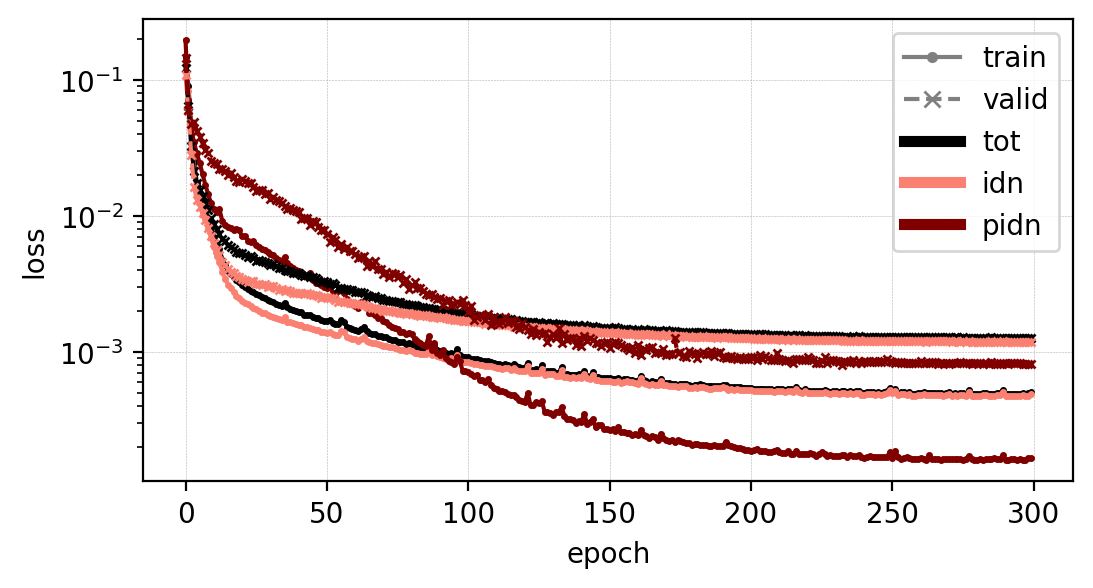

In [13]:
tic = time()
train.train_ae(model,
               train_rows, valid_rows,
               trainAEloss, validAEloss,
               optimiser=optimizerAE,
               nb_epochs=nb_epochs,
               batch_size=ae_batch,
               scheduler=scheduler,
               print_every=25)
loss.plot({'train':trainAEloss, 'valid':validAEloss})

## Training the nODE

Then, the autoencoder is frozen and we continue training on only the ODE. We use a smaller number of evol to focus on the neighboring gradient. The ODE is does NOT like to move so crank up that learning rate

In [ ]:
trainODEloss = loss.setup_loss("abs")
validODEloss = loss.setup_loss("abs")
exit_code = 0 # nODE solver status, optional

In [ ]:
nb_epochs = 50
lr = 1e-2
optimizerODE = torch.optim.Adam(model.parameters(), lr=lr)
model.freeze(encoder=True, decoder=True)

exit_code += train.train(model,
             data_loader, valid_loader,
             trainODEloss, validODEloss,
             optimiser=optimizerODE, 
             nb_epochs=nb_epochs,
             nb_evol=4,
             batch_size=32)
loss.plot({'train':trainODEloss, 'valid':validODEloss})

## Training everything

Joint training, like old versions. I'm a little worried this just results in the autoencoder doing the ODE's job, but whatevs.

In [ ]:
trainFULLloss = loss.setup_loss("abs_idn_pidn", weights=[1,1,.1])
validFULLloss = loss.setup_loss("abs_idn_pidn", weights=[1,1,.1])
exit_code = 0 # nODE solver status, optional

In [ ]:
nb_epochs = 50
lr = 3e-4
lr_min = 1e-5
steps_per_epoch = sum(-(-(n.shape[1]-1) // ae_batch) for n, _, _ in data_loader)
optimizerFULL = torch.optim.Adam(model.parameters(), lr=lr)
schedulerFULL = torch.optim.lr_scheduler.CosineAnnealingLR(optimizerFULL, 
                    T_max=nb_epochs*steps_per_epoch, eta_min=lr_min)
model.freeze()


In [ ]:

exit_code += train.train(model,
             data_loader, valid_loader,
             trainFULLloss, validFULLloss,
             optimiser=optimizerFULL, 
             scheduler=schedulerFULL,
             nb_epochs=nb_epochs,
             nb_evol=meta.nb_evol,
             batch_size=32)
loss.plot({'train':trainFULLloss, 'valid':validFULLloss})

## Saving the model
Save the losses & specifics of the data set.

In [ ]:
print('path:', path)

trainAEloss.save(path+'/train')
validAEloss.save(path+'/valid')

Save the model

In [ ]:
torch.save(model.state_dict(),path+'/nn/nn.pt')

Plot the evolution of the loss and save the figure.



In [ ]:
plt.close()
fig, axes = plt.subplots(3)
axes = axes.ravel()
loss.plot({'train':trainAEloss, 'valid':validAEloss}, ax=axes[0])
loss.plot({'train':trainODEloss, 'valid':validODEloss}, ax=axes[1])
loss.plot({'train':trainFULLloss, 'valid':validFULLloss}, ax=axes[2])
plt.savefig(path+'/figs/loss.png')
plt.show()

## Testing the autoencoder

Test on the held-out models in `data/test/` with the error metric of Maes et al. (2024), Eq. 23:

$$ {\rm error} = \frac{\log_{10}\boldsymbol{n}-\log_{10}\hat{\boldsymbol{n}}}{\log_{10}\boldsymbol{n}}, $$

executed element-wise, summed over the species and averaged over the data points. Only the reconstruction (`idn`) is meaningful here: the latent ODE has not been trained, so the rollout error (`evol`) of `testModel` is not stored.

Reference (`CLAUDE.md`): recipe AE ≈ 7.6 (valid) / 6.0 (test); shipped `nn7` 3.5 / 3.5.

In [ ]:
testpaths  = ['low_dens', 'mid_dens', 'high_dens']
test_items = {}
for tp in testpaths:
    _, (n, p, dt), _ = ds.get_test_data(parentpath+'data/test/'+tp, meta)
    test_items[tp] = (n[None], p[None], dt[None])   ## add the batch dimension a DataLoader would add

test_errors = {}
for tp, item in test_items.items():
    errors, times = test.testModel(model, [item])
    test_errors[tp] = errors['idn']
test_errors['mean'] = sum(test_errors[tp] for tp in testpaths) / len(testpaths)

valid_errors, _ = test.testModel(model, valid_loader)
test_errors['valid'] = valid_errors['idn']

print('AE reconstruction error (Eq. 23):', {k: round(v, 2) for k, v in test_errors.items()})

### Saving the outcome of the tests

In [ ]:
meta.updateMeta(test_errors={'idn_'+k: v for k, v in test_errors.items()})

### Plotting the reconstruction
Every data point of the test model is passed through the autoencoder, $(\hat{\boldsymbol{n}}, \hat{\boldsymbol{p}}) = D(E(\boldsymbol{p}, \boldsymbol{n}))$, without time evolution.

In [14]:
import importlib as imp
imp.reload(plotting)
testpath = 'data/test/mid_dens'

In [ ]:
fig, axes = plotting.plot_hairs(model, meta, testpath, nb_evol=64, 
               specs=['CO', 'H2O', 'OH', 'C2H2', 'C2H', 'CH3C5NH+', 'C10H2+'], 
               interval=5)
fig.savefig(path+'/figs/hairs.png')
plt.show()

> Train state: False
Paths found: 13
Valid paths: 3
Test paths: 0
Loading 1D CSE model from data/test/mid_dens


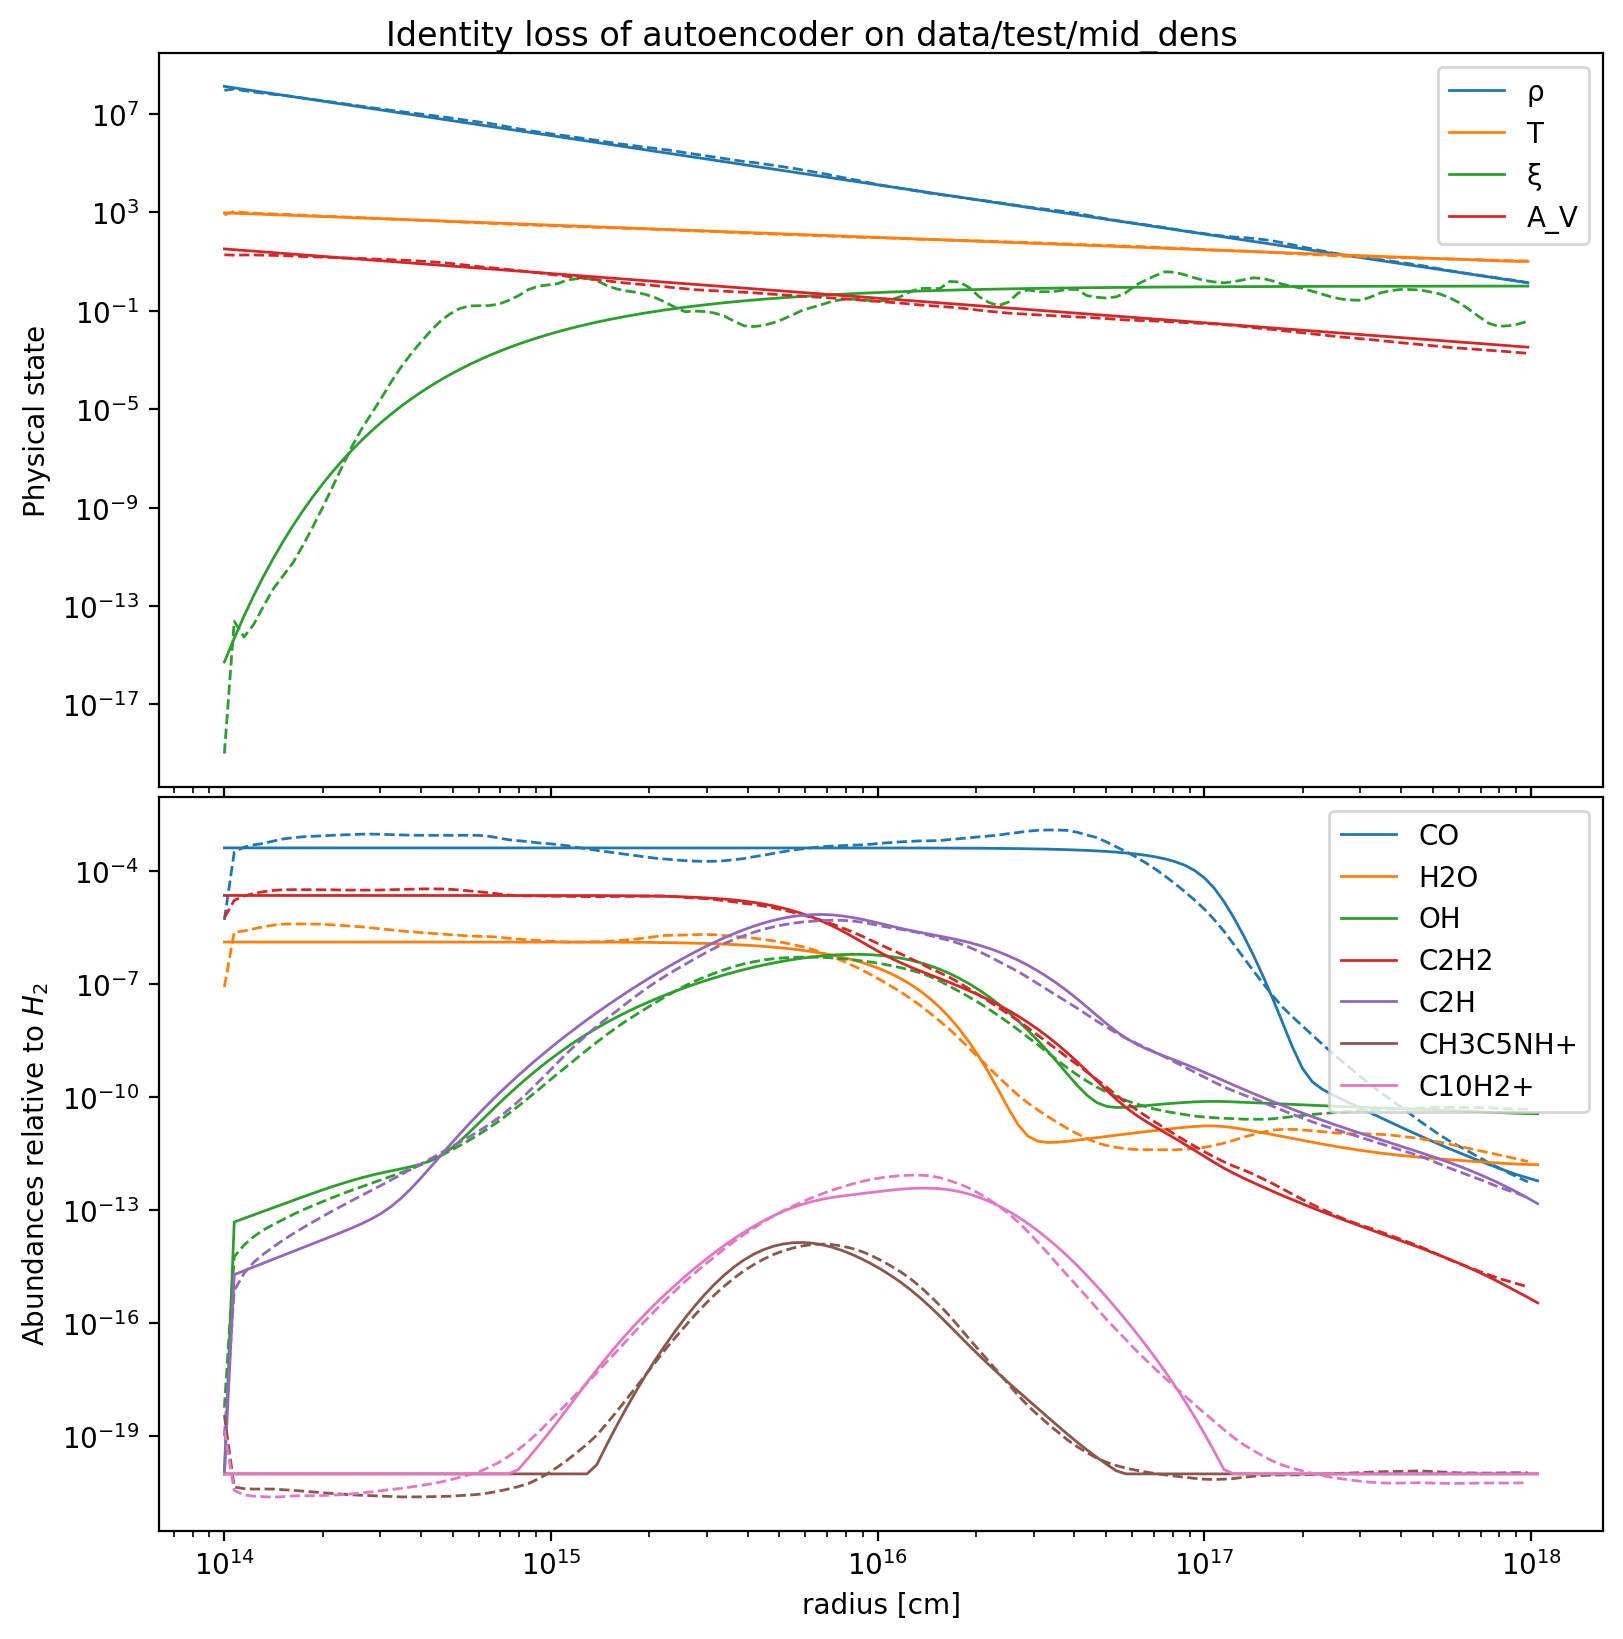

In [15]:
fig, axes = plotting.plot_identity(model, meta, testpath,
               specs=['CO', 'H2O', 'OH', 'C2H2', 'C2H', 'CH3C5NH+', 'C10H2+'])
fig.savefig(path+'/figs/identity.png')
plt.show()

In [ ]:
model1D, (n, p, dt), info = ds.get_test_data(testpath, meta)
with torch.no_grad():
    n_hat, status = model.rollout(n[0:1], p[None], dt[None])

n_evol = torch.cat((n[0:1], n_hat[0]), dim=0)      ## (N, 468)
n_real = ds.get_n(n)
n_evol = ds.get_n(n_evol)

fig12_specs = ['CO', 'H2O', 'OH', 'C2H2', 'C2H', 'CH3C5NH+', 'C10H2+']

fig, axes = plotting.plot_n(model1D, '1DCSE', n_real, n_evol, specs=fig12_specs, step=False)

#axes[2].set_ylim(-.5,.1)
fig.suptitle(f'MACE v2, {testpath}', y=1.0)
fig.savefig(path+'/figs/preds.png')
plt.show()

In [ ]:
plotting.diagnose(model, meta, testpath, nb_evol=64, 
               specs=['CO', 'H2O', 'OH', 'C2H2', 'C2H', 'CH3C5NH+', 'C10H2+'], 
               interval=5)